# Encoder input, T = 48, benign only: genuine windows for one-class training

This notebook builds the **benign-only** version of the T = 48, train / val / test = 80 / 10 / 10 encoder input
(`T48_tvt`), for one-class (genuine-only) autoencoder training: the model learns what genuine motion looks like from
genuine windows only, and attacks are what it reconstructs badly. Phase 1 trains on genuine windows from vehicles that
are never attackers, and the normalisation statistics come from genuine training windows only.

It reads the prepared files in `src/data/prepared_data/` (written by `src/pipeline/input_representation.ipynb`) and
writes windows of **at most 48 messages × 13 features**, each with a mask, exactly as `encoder_input_T48_tvt.ipynb`
does: the same two GridSybil scenario folders, the same crop (non-overlapping pieces of at most 48 messages, every
piece padded to 48 rows), the same mask, the same 13 features.

**What changes against `T48_tvt`.**

- **Benign only in train / val / test.** Only links whose sender vehicle has code 0 (Benign) are kept.
- **Attacker vehicles excluded.** A link is also dropped if its physical sender vehicle is an attacker (code 16)
  anywhere in its scenario folder, according to `index.json` labels or to the `receiver_attack_code` of that
  vehicle's own prepared file in the run. In VeReMi the attack code belongs to the vehicle for the whole run, so an
  attacker's own-pseudonym (genuine-looking) messages are already labelled GridSybil and never reach the benign class;
  the check makes the rule explicit and counts what it removes.
- **`test_gridsybil/`.** The GridSybil windows of the **test** vehicles are written as a fourth folder, so a one-class
  model can be evaluated on benign test vs GridSybil test with one consistent normalisation. No GridSybil window
  enters train or val.
- **Normalisation** mean / std are fitted on the real rows of the **benign train** windows of this dataset and applied
  to every split, `test_gridsybil` included.

**Split: unchanged (RULE 3).** The vehicle split is computed exactly as in `T48_tvt` (seeded (0) shuffle per
(group, class) over benign and GridSybil vehicles, 80 / 10 / 10): every vehicle keeps its `T48_tvt` split, and this
dataset only keeps a subset of each split. There is **no split change**. Output folder:
`src/data/encoder_input/benign_gridsybil/T48_benign/` (`train/b48`, `val/b48`, `test/b48`, `test_gridsybil/b48`).

**One missing value.** The first message of a link has no previous message, so its `log_dtau` is missing
(`null` in the prepared file, `NaN` here). After normalisation it becomes 0, which is the train mean.

This first half builds the windows in memory (`windows`); the second half normalises them and writes JSON.


In [1]:
from __future__ import annotations

import dataclasses
import json
import multiprocessing
import os
import pathlib
import time
from typing import Any

import numpy as np
import pandas as pd

# Run from the repository root, so that every relative path resolves the same way every time.
for _folder in [
    pathlib.Path.cwd(),
    *pathlib.Path.cwd().parents,
]:  # notebooks live in src/<folder>/; work from the repo root
    if (_folder / "CLAUDE.md").is_file():
        os.chdir(_folder)
        break
assert (
    pathlib.Path("CLAUDE.md").is_file() and pathlib.Path("data").is_dir()
), f"run this notebook from the repository root (now in {pathlib.Path.cwd()})"
print("working directory:", pathlib.Path.cwd())

working directory: /Users/bibekgupta/Downloads/projects/sybil-llm


## Settings

Everything that can change lives in one frozen dataclass; the second half stores it next to the output.


In [2]:
@dataclasses.dataclass(frozen=True)
class EncoderInputSettings:
    """Settings for building fixed-length encoder windows.

    Attributes:
        prepared_dir: Folder of prepared files plus `index.json` (read only here).
        out_dir: Where the sharded JSON output goes (gitignored).
        seq_len: Maximum messages per window (T).
        crop_stride: Messages between the starts of two crops of a link; equal to `seq_len` means no overlap.
        buckets: Allowed window lengths; a window is padded up to the smallest bucket that fits it.
        min_messages: Windows with fewer real messages are dropped and counted (1 keeps every window).
        scenarios: Scenario folders to read.
        keep_codes: Sender attack codes to keep (0 benign, 16 GridSybil).
        shard_size: Windows per output shard.
        decimals: Decimals kept for every float written to disk.
        workers: Number of worker processes for reading.
        allowed_out_root: The only folder the writer may write into.
        test_frac: Share of sender vehicles per (scenario group, class) that go to test.
        val_frac: Share of sender vehicles per (scenario group, class) that go to val (taken after test).
        split_seed: Seed of the vehicle shuffle for the train / val / test split.
        benign_code: Attack code of genuine senders; train / val / test keep only these.
        attack_codes: Attack codes that make a vehicle an attacker; its links never enter the benign class.
        attack_test_split: Name of the extra folder with the attack windows of the test vehicles.
        reference_metadata: `metadata.json` of `T48_tvt`, read only to compare the normalisation.
    """

    prepared_dir: str = "src/data/prepared_data"
    out_dir: str = "src/data/encoder_input/benign_gridsybil/T48_benign"
    seq_len: int = 48
    crop_stride: int = 48
    buckets: tuple[int, ...] = (48,)
    min_messages: int = 1
    scenarios: tuple[str, ...] = ("GridSybil_0709", "GridSybil_1416")
    keep_codes: tuple[int, ...] = (0, 16)
    shard_size: int = 10000
    decimals: int = 4
    workers: int = 10
    allowed_out_root: str = "src/data/encoder_input"
    test_frac: float = 0.10
    val_frac: float = 0.10
    split_seed: int = 0
    benign_code: int = 0
    attack_codes: tuple[int, ...] = (16,)
    attack_test_split: str = "test_gridsybil"
    reference_metadata: str = "src/data/encoder_input/benign_gridsybil/T48_tvt/metadata.json"

    def __post_init__(self) -> None:
        if self.seq_len < 1:
            raise ValueError(f"seq_len must be >= 1, got {self.seq_len}")
        if not 1 <= self.crop_stride <= self.seq_len:
            raise ValueError(f"crop_stride must be in [1, seq_len], got {self.crop_stride}")
        if list(self.buckets) != sorted(set(self.buckets)) or self.buckets[-1] != self.seq_len:
            raise ValueError(f"buckets must be increasing and end at seq_len, got {self.buckets}")
        if not 1 <= self.min_messages <= self.seq_len:
            raise ValueError(f"min_messages must be in [1, seq_len], got {self.min_messages}")
        if self.workers < 1:
            raise ValueError(f"workers must be >= 1, got {self.workers}")
        if not 0.0 < self.test_frac < 1.0:
            raise ValueError(f"test_frac must be in (0, 1), got {self.test_frac}")
        if not 0.0 < self.val_frac < 1.0 or self.test_frac + self.val_frac >= 1.0:
            raise ValueError(f"val_frac must be in (0, 1) with test_frac + val_frac < 1, got {self.val_frac}")
        if self.benign_code not in self.keep_codes or not set(self.attack_codes) <= set(self.keep_codes):
            raise ValueError(f"benign_code and attack_codes must be in keep_codes, got {self.keep_codes}")
        if self.shard_size < 1:
            raise ValueError(f"shard_size must be >= 1, got {self.shard_size}")
        if pathlib.Path(self.out_dir).resolve().is_relative_to(pathlib.Path("data").resolve()):
            raise ValueError("out_dir must not be inside data/ (read-only, RULE 2)")


SETTINGS = EncoderInputSettings()

FEATURE_NAMES: tuple[str, ...] = (
    "claimed_pos_x",
    "claimed_pos_y",
    "rx_pos_x",
    "rx_pos_y",
    "claimed_vel_x",
    "claimed_vel_y",
    "rx_vel_x",
    "rx_vel_y",
    "claimed_acl_x",
    "claimed_acl_y",
    "range",
    "bearing",
    "log_dtau",
)
N_FEATURES = len(FEATURE_NAMES)
LOG_DTAU_COL = FEATURE_NAMES.index("log_dtau")
print(SETTINGS)

EncoderInputSettings(prepared_dir='src/data/prepared_data', out_dir='src/data/encoder_input/benign_gridsybil/T48_benign', seq_len=48, crop_stride=48, buckets=(48,), min_messages=1, scenarios=('GridSybil_0709', 'GridSybil_1416'), keep_codes=(0, 16), shard_size=10000, decimals=4, workers=10, allowed_out_root='src/data/encoder_input', test_frac=0.1, val_frac=0.1, split_seed=0, benign_code=0, attack_codes=(16,), attack_test_split='test_gridsybil', reference_metadata='src/data/encoder_input/benign_gridsybil/T48_tvt/metadata.json')


## Labels from `index.json`, split 80 / 10 / 10 by vehicle

`index.json` holds the attack code of every sender vehicle per scenario folder and the vehicle-grouped split.
`IndexBook` answers two questions for a sender: _what is its label?_ and _which split is it in?_

The split is rebuilt here: `IndexBook.split_train_val_test` replaces the index's four-way split with a seeded
80 / 10 / 10 train / val / test split of the sender vehicles, stratified by scenario group and class. In each
(group, class) stratum it uses **the same seeded shuffle** as `split_train_test` (the 90 / 10 split of the T64 / T48
inputs): test = the first `n_test` vehicles (unchanged), val = the next `n_val = max(1, round(val_frac × stratum))`,
train = the rest. The cell checks that the test vehicles equal those of `split_train_test`.

**Benign-only note.** The split is computed over **both** classes (codes 0 and 16), as in `T48_tvt`: the seeded
shuffle draws the strata one after the other, so computing it over benign vehicles only would give the 1416 benign
stratum a different order. Every vehicle therefore gets exactly its `T48_tvt` split; the benign-only selection
below only removes windows.


In [3]:
class IndexBook:
    """Sender labels and the vehicle-grouped split, read from `index.json`.

    Attributes:
        labels: Scenario folder -> {vehicle id -> attack code}.
        class_names: Attack code -> class name.
        split_of_vehicle: `"<group>:<vehicle>"` -> split name.
        source: Path and provenance of the index file.
    """

    def __init__(self, index_path: pathlib.Path) -> None:
        """Loads the index.

        Args:
            index_path: Path to `index.json`.
        """
        index = json.loads(index_path.read_text())
        if list(index["features"]) != list(FEATURE_NAMES):
            raise ValueError(f"feature order in {index_path} differs from FEATURE_NAMES")
        self.labels: dict[str, dict[int, int]] = {
            scenario: {int(vehicle): int(code) for vehicle, code in codes.items()}
            for scenario, codes in index["labels"].items()
        }
        self.class_names: dict[int, str] = {int(code): name for code, name in index["class_names"].items()}
        self.split_of_vehicle: dict[str, str] = {}
        for split, keys in index["split"]["vehicles"].items():
            for key in keys:
                if key in self.split_of_vehicle:
                    raise ValueError(f"vehicle {key} is in two splits")  # RULE 3
                self.split_of_vehicle[key] = split
        self.split_names: tuple[str, ...] = tuple(index["split"]["vehicles"])
        self.source = {"path": str(index_path), "provenance": index.get("provenance", {})}

    def label(self, scenario: str, sender: int) -> int:
        """Returns the sender's attack code, or -1 if it is not known."""
        return self.labels.get(scenario, {}).get(sender, -1)

    def split_train_test(self, scenarios: tuple[str, ...], codes: tuple[int, ...], test_frac: float, seed: int) -> dict:
        """Replaces the split with a seeded train / test split of the vehicles, stratified by (group, class).

        Every vehicle with a wanted code in the given scenario folders gets exactly one split (RULE 3: by vehicle).

        Returns:
            Vehicles per split and per (group, class) stratum, for the report and metadata.
        """
        strata: dict[tuple[str, int], set[str]] = {}
        for scenario in scenarios:
            for vehicle, code in self.labels.get(scenario, {}).items():
                if code in codes:
                    strata.setdefault((group_of(scenario), code), set()).add(f"{group_of(scenario)}:{vehicle}")
        rng = np.random.default_rng(seed)
        split_of: dict[str, str] = {}
        report = {}
        for (group, code), keys in sorted(strata.items()):
            ordered = sorted(keys)
            rng.shuffle(ordered)
            n_test = max(1, int(round(test_frac * len(ordered))))
            for k, key in enumerate(ordered):
                if key in split_of:
                    raise ValueError(f"vehicle {key} is in two strata")  # RULE 3
                split_of[key] = "test" if k < n_test else "train"
            report[f"{group}/{self.class_names.get(code, code)}"] = {"train": len(ordered) - n_test, "test": n_test}
        self.split_of_vehicle = split_of
        self.split_names = ("train", "test")
        return {
            "rule": f"seeded ({seed}) shuffle per (group, class); {test_frac:.0%} of vehicles to test",
            "per_stratum": report,
            "vehicles": {s: sum(v == s for v in split_of.values()) for s in self.split_names},
        }

    def split_train_val_test(
        self, scenarios: tuple[str, ...], codes: tuple[int, ...], test_frac: float, val_frac: float, seed: int
    ) -> dict:
        """Replaces the split with a seeded train / val / test split of the vehicles, stratified by (group, class).

        Uses the same strata, order and seeded shuffle as `split_train_test`, so test is exactly the same set of
        vehicles: test = the first n_test of each shuffled stratum, val = the next n_val, train = the rest.
        Every vehicle with a wanted code in the given scenario folders gets exactly one split (RULE 3: by vehicle).

        Returns:
            Vehicles per split and per (group, class) stratum, plus the vehicle ids of every split.
        """
        strata: dict[tuple[str, int], set[str]] = {}
        for scenario in scenarios:
            for vehicle, code in self.labels.get(scenario, {}).items():
                if code in codes:
                    strata.setdefault((group_of(scenario), code), set()).add(f"{group_of(scenario)}:{vehicle}")
        rng = np.random.default_rng(seed)
        split_of: dict[str, str] = {}
        report = {}
        for (group, code), keys in sorted(strata.items()):
            ordered = sorted(keys)
            rng.shuffle(ordered)
            n_test = max(1, int(round(test_frac * len(ordered))))
            n_val = max(1, int(round(val_frac * len(ordered))))
            if n_test + n_val >= len(ordered):
                raise ValueError(f"stratum {group}/{code} has {len(ordered)} vehicles: no train vehicle left")
            for k, key in enumerate(ordered):
                if key in split_of:
                    raise ValueError(f"vehicle {key} is in two strata")  # RULE 3
                split_of[key] = "test" if k < n_test else ("val" if k < n_test + n_val else "train")
            report[f"{group}/{self.class_names.get(code, code)}"] = {
                "train": len(ordered) - n_test - n_val,
                "val": n_val,
                "test": n_test,
            }
        self.split_of_vehicle = split_of
        self.split_names = ("train", "val", "test")
        return {
            "rule": (
                f"seeded ({seed}) shuffle per (group, class); first {test_frac:.0%} of vehicles to test "
                f"(same as the 90 / 10 split), next {val_frac:.0%} to val, rest to train"
            ),
            "per_stratum": report,
            "vehicles": {s: sum(v == s for v in split_of.values()) for s in self.split_names},
            "vehicle_ids": {s: sorted(k for k, v in split_of.items() if v == s) for s in self.split_names},
        }

    def split(self, scenario: str, sender: int) -> str | None:
        """Returns the sender vehicle's split, or None if the vehicle is not in the split."""
        return self.split_of_vehicle.get(f"{group_of(scenario)}:{sender}")


def group_of(scenario: str) -> str:
    """Returns the time-window group of a scenario folder, e.g. 'GridSybil_0709' -> '0709'."""
    return scenario.rsplit("_", 1)[1]


INDEX = IndexBook(pathlib.Path(SETTINGS.prepared_dir) / "index.json")
_reference = INDEX.split_train_test(SETTINGS.scenarios, SETTINGS.keep_codes, SETTINGS.test_frac, SETTINGS.split_seed)
_reference_test = {k for k, v in INDEX.split_of_vehicle.items() if v == "test"}
SPLIT_REPORT = INDEX.split_train_val_test(
    SETTINGS.scenarios, SETTINGS.keep_codes, SETTINGS.test_frac, SETTINGS.val_frac, SETTINGS.split_seed
)
_ids = SPLIT_REPORT["vehicle_ids"]
assert set(_ids["test"]) == _reference_test, "test vehicles differ from the 90 / 10 split"
assert not (set(_ids["train"]) & set(_ids["val"])) and not (set(_ids["train"]) | set(_ids["val"])) & set(_ids["test"])
assert sum(len(v) for v in _ids.values()) == len(INDEX.split_of_vehicle)  # RULE 3: every vehicle in exactly one split
print(json.dumps({k: v for k, v in SPLIT_REPORT.items() if k != "vehicle_ids"}, indent=1))
print("test vehicles identical to the 90 / 10 split:", len(_reference_test))
print("splits:", INDEX.split_names, "| vehicles in split:", len(INDEX.split_of_vehicle))
print("class names:", INDEX.class_names)

{
 "rule": "seeded (0) shuffle per (group, class); first 10% of vehicles to test (same as the 90 / 10 split), next 10% to val, rest to train",
 "per_stratum": {
  "0709/Benign": {
   "train": 2277,
   "val": 284,
   "test": 284
  },
  "0709/GridSybil": {
   "train": 975,
   "val": 122,
   "test": 122
  },
  "1416/Benign": {
   "train": 948,
   "val": 118,
   "test": 118
  },
  "1416/GridSybil": {
   "train": 405,
   "val": 51,
   "test": 51
  }
 },
 "vehicles": {
  "train": 4605,
  "val": 575,
  "test": 575
 }
}
test vehicles identical to the 90 / 10 split: 575
splits: ('train', 'val', 'test') | vehicles in split: 5755
class names: {-1: 'Unknown', 0: 'Benign', 16: 'GridSybil', 17: 'DataReplaySybil', 18: 'DoSRandomSybil', 19: 'DoSDisruptiveSybil'}


## Reading the prepared files

There is one prepared file per receiving car. Reading them is the slow part, so it runs in parallel worker
processes. The worker function sits at the top level of the notebook so worker processes can find it
(`fork` start method). Each worker returns the links of one file with their 13-feature rows as a float32
array; the missing first `log_dtau` becomes `NaN`.


In [4]:
def read_prepared_file(path_str: str) -> dict[str, Any]:
    """Reads one prepared receiver file (worker function, must stay top level).

    Args:
        path_str: Path of the prepared JSON file.

    Returns:
        The receiver, its own attack code, its run, and a list of links, each with `sender`, `sender_pseudo` and `x`
        (float32 array of shape (messages, 13), missing values as NaN).
    """
    record = json.loads(pathlib.Path(path_str).read_text())
    links = []
    for link in record["links"]:
        x = np.array(link["x"], dtype=np.float32).reshape(-1, N_FEATURES)  # JSON null -> NaN
        links.append({"sender": int(link["sender"]), "sender_pseudo": int(link["sender_pseudo"]), "x": x})
    return {
        "path": path_str,
        "receiver": int(record["receiver"]),
        "receiver_attack_code": int(record["receiver_attack_code"]),
        "run": record["run"],
        "links": links,
    }


class PreparedReader:
    """Reads every prepared receiver file of the chosen scenario folders in parallel."""

    def __init__(self, settings: EncoderInputSettings) -> None:
        """Stores the settings.

        Args:
            settings: The notebook settings.
        """
        self.settings = settings
        self.root = pathlib.Path(settings.prepared_dir)

    def files(self) -> list[pathlib.Path]:
        """Lists the prepared files, sorted so the window order is reproducible."""
        found: list[pathlib.Path] = []
        for scenario in self.settings.scenarios:
            folder = self.root / scenario
            if not folder.is_dir():
                raise FileNotFoundError(f"missing scenario folder {folder}")
            found.extend(sorted(folder.glob("*/traceJSON-*.json")))
        return found

    def read(self) -> list[dict[str, Any]]:
        """Reads all files; results come back in the same order as `files()`."""
        paths = [str(path) for path in self.files()]
        context = multiprocessing.get_context("fork")
        with context.Pool(self.settings.workers) as pool:
            return pool.map(read_prepared_file, paths, chunksize=16)

## Cropping links into 48-row windows

`LinkWindower` crops each link into non-overlapping pieces of at most 48 messages (a link of `n` messages gives
`ceil(n / 48)` windows). Every window sits in a 48-row array: its real rows first, then zero rows; `mask` is 1
on the real rows. (The `bucket` column is always 48 here; with several buckets the second half would cut each
window to its bucket size.) The windower first counts all windows,
then fills pre-allocated arrays, so memory stays at one copy.


In [5]:
def crop_starts(n_messages: int, max_len: int, stride: int) -> list[int]:
    """Returns the start of every crop of a link, stopping at the first crop that reaches the link's end.

    Args:
        n_messages: Messages in the link.
        max_len: Maximum messages per crop (T).
        stride: Messages between two crop starts (`max_len` = no overlap).

    Returns:
        Start offsets; with `stride == max_len` every message is in exactly one crop.
    """
    starts = [0]
    while starts[-1] + max_len < n_messages:
        starts.append(starts[-1] + stride)
    return starts


def bucket_of(n_messages: int, buckets: tuple[int, ...]) -> int:
    """Returns the smallest bucket that holds `n_messages` rows."""
    for size in buckets:
        if n_messages <= size:
            return size
    raise ValueError(f"{n_messages} messages do not fit the largest bucket {buckets[-1]}")


@dataclasses.dataclass
class Windows:
    """Cropped, bucketed windows held in memory.

    Attributes:
        x_raw: float32 (N, T, 13); real rows hold raw values, rows beyond `n_messages` are 0,
            the missing first log_dtau of a link is NaN.
        mask: uint8 (N, T); 1 for the first `n_messages` rows (real), 0 for padding.
        meta: One row per window (ids, provenance, n_messages, bucket, label, split).
        counts: Links kept / dropped, messages, windows per split and class.
    """

    x_raw: np.ndarray
    mask: np.ndarray
    meta: pd.DataFrame
    counts: dict[str, Any]


class LinkWindower:
    """Turns prepared files into labelled, split, cropped and bucketed windows."""

    def __init__(self, settings: EncoderInputSettings, index: IndexBook) -> None:
        """Stores collaborators.

        Args:
            settings: The notebook settings.
            index: Labels and split lookup.
        """
        self.settings = settings
        self.index = index

    def build(self, files: list[dict[str, Any]]) -> Windows:
        """Selects the kept links, crops them, and assigns each window a bucket and a mask.

        Args:
            files: Output of `PreparedReader.read()`.

        Returns:
            The windows with their mask, meta table and counts.
        """
        s = self.settings
        t = s.seq_len
        kept, drops = self._select(files)
        pieces = [
            (i, start, min(len(link["x"]) - start, t))
            for i, (_, link, _, _) in enumerate(kept)
            for start in crop_starts(len(link["x"]), t, s.crop_stride)
        ]
        short = [p for p in pieces if p[2] < s.min_messages]
        pieces = [p for p in pieces if p[2] >= s.min_messages]
        x_raw = np.zeros((len(pieces), t, N_FEATURES), dtype=np.float32)
        mask = np.zeros((len(pieces), t), dtype=np.uint8)
        rows: list[dict[str, Any]] = []
        link_k: dict[int, int] = {}
        for w, (i, start, n) in enumerate(pieces):
            record, link, code, split = kept[i]
            k = link_k[i] = link_k.get(i, -1) + 1
            x_raw[w, :n] = link["x"][start : start + n]
            mask[w, :n] = 1
            receiver_file = str(pathlib.Path(record["path"]).relative_to(s.prepared_dir))
            rows.append(
                {
                    "window_id": f"{receiver_file}#{link['sender_pseudo']}-{link['sender']}#{k}",
                    "scenario": record["run"].split("/", 1)[0],
                    "run": record["run"],
                    "receiver_file": receiver_file,
                    "receiver": record["receiver"],
                    "sender": link["sender"],
                    "sender_pseudo": link["sender_pseudo"],
                    "link_window_index": k,
                    "n_messages": n,
                    "bucket": bucket_of(n, s.buckets),
                    "label": code,
                    "label_name": self.index.class_names.get(code, str(code)),
                    "is_attack": int(code != 0),
                    "split": split,
                }
            )
        meta = pd.DataFrame(rows)
        if not meta["window_id"].is_unique:
            raise ValueError("window ids are not unique")
        drops["below_min_messages"] = {"windows": len(short), "messages": int(sum(p[2] for p in short))}
        return Windows(x_raw=x_raw, mask=mask, meta=meta, counts=self._counts(kept, drops, meta))

    def _select(self, files: list[dict[str, Any]]) -> tuple[list[tuple], dict[str, dict[str, int]]]:
        """Keeps links whose sender code is wanted and whose sender vehicle has a split."""
        kept: list[tuple] = []
        drops = {reason: {"links": 0, "messages": 0} for reason in ("unknown_label", "other_code", "no_split", "empty")}
        for record in files:
            scenario = record["run"].split("/", 1)[0]
            for link in record["links"]:
                code = self.index.label(scenario, link["sender"])
                split = self.index.split(scenario, link["sender"])
                if len(link["x"]) == 0:
                    reason = "empty"
                elif code == -1:
                    reason = "unknown_label"
                elif code not in self.settings.keep_codes:
                    reason = "other_code"
                elif split is None:
                    reason = "no_split"
                else:
                    kept.append((record, link, code, split))
                    continue
                drops[reason]["links"] += 1
                drops[reason]["messages"] += len(link["x"])
        return kept, drops

    def _counts(self, kept: list[tuple], drops: dict[str, dict[str, int]], meta: pd.DataFrame) -> dict[str, Any]:
        """Summarises what was kept and dropped, per split × bucket × class."""
        per = meta.groupby(["split", "bucket", "label_name"]).agg(
            windows=("n_messages", "size"), messages=("n_messages", "sum"), rows=("bucket", "sum")
        )
        per["padding_share"] = 1.0 - per["messages"] / per["rows"]
        return {
            "files": len({record["path"] for record, *_ in kept}),
            "links_kept": len(kept),
            "messages_kept": int(sum(len(link["x"]) for _, link, _, _ in kept)),
            "messages_in_windows": int(meta["n_messages"].sum()) if len(meta) else 0,
            "dropped": drops,
            "windows": int(len(meta)),
            "per_split_bucket_class": {
                f"{split}/b{bucket:02d}/{name}": {
                    "windows": int(row["windows"]),
                    "messages": int(row["messages"]),
                    "padding_share": round(float(row["padding_share"]), 4),
                }
                for (split, bucket, name), row in per.iterrows()
            },
        }

## Build the windows


In [6]:
_start = time.perf_counter()
_files = PreparedReader(SETTINGS).read()
print(f"read {len(_files)} prepared files in {time.perf_counter() - _start:.1f} s")
windows = LinkWindower(SETTINGS, INDEX).build(_files)
print(
    f"built {len(windows.meta):,} benign + GridSybil windows in {time.perf_counter() - _start:.1f} s total "
    f"(x_raw {windows.x_raw.nbytes / 1e9:.2f} GB)"
)
print(json.dumps({k: v for k, v in windows.counts.items() if k != "per_split_bucket_class"}, indent=1))

read 5755 prepared files in 1.9 s


built 395,851 benign + GridSybil windows in 7.3 s total (x_raw 0.99 GB)
{
 "files": 5752,
 "links_kept": 354197,
 "messages_kept": 6980356,
 "messages_in_windows": 6980356,
 "dropped": {
  "unknown_label": {
   "links": 271,
   "messages": 4123
  },
  "other_code": {
   "links": 0,
   "messages": 0
  },
  "no_split": {
   "links": 0,
   "messages": 0
  },
  "empty": {
   "links": 0,
   "messages": 0
  },
  "below_min_messages": {
   "windows": 0,
   "messages": 0
  }
 },
 "windows": 395851
}


## Benign only: attacker vehicles out, GridSybil test windows aside

`AttackerRegistry` lists every physical vehicle that is an attacker (code 16) in a scenario folder, from two
sources: the `index.json` labels (per scenario folder) and the `receiver_attack_code` of each vehicle's own prepared
file (per run). Vehicle ids never repeat across the runs of a scenario folder (checked below), so the two are the same
grouping. `BenignOnlySelector` then keeps

- every benign window (sender code 0) whose sender vehicle is **not** in the registry, in its own split;
- every GridSybil window of a **test** vehicle, moved to the `test_gridsybil` split;

and drops GridSybil windows of train / val vehicles. It counts what each rule removes per split (windows, messages,
vehicles, links). A window's receiver may still be an attacker car (its own GPS fix is genuine); that number is
reported, not filtered.


In [7]:
class AttackerRegistry:
    """Physical vehicles that are attackers anywhere in a scenario folder.

    Attributes:
        from_index: Scenario folder -> attacker vehicle ids from the `index.json` labels.
        from_files: Scenario folder -> attacker vehicle ids from the receivers' own `receiver_attack_code`.
        receiver_code: (run, receiver vehicle) -> the receiver's attack code.
    """

    def __init__(self, index: IndexBook, files: list[dict[str, Any]], settings: EncoderInputSettings) -> None:
        """Builds both attacker lists.

        Args:
            index: Labels and split lookup.
            files: Output of `PreparedReader.read()`.
            settings: The notebook settings.

        Raises:
            ValueError: If a vehicle id appears in two runs of one scenario folder (the grouping would be ambiguous).
        """
        codes = set(settings.attack_codes)
        self.from_index: dict[str, set[int]] = {
            scenario: {v for v, c in index.labels.get(scenario, {}).items() if c in codes}
            for scenario in settings.scenarios
        }
        self.from_files: dict[str, set[int]] = {scenario: set() for scenario in settings.scenarios}
        self.receiver_code: dict[tuple[str, int], int] = {}
        run_of: dict[tuple[str, int], str] = {}
        for record in files:
            scenario = record["run"].split("/", 1)[0]
            key = (scenario, record["receiver"])
            if run_of.setdefault(key, record["run"]) != record["run"]:
                raise ValueError(f"vehicle {key} appears in two runs: {run_of[key]}, {record['run']}")
            self.receiver_code[(record["run"], record["receiver"])] = record["receiver_attack_code"]
            if record["receiver_attack_code"] in codes:
                self.from_files[scenario].add(record["receiver"])

    def is_attacker(self, scenario: str, vehicle: int) -> bool:
        """True if the vehicle is an attacker in the scenario folder by either source."""
        return vehicle in self.from_index.get(scenario, set()) or vehicle in self.from_files.get(scenario, set())

    def summary(self) -> dict[str, Any]:
        """Attacker counts per scenario folder and source, and where the sources disagree."""
        return {
            scenario: {
                "index_labels": len(self.from_index[scenario]),
                "receiver_files": len(self.from_files[scenario]),
                "union": len(self.from_index[scenario] | self.from_files[scenario]),
                "only_in_index": len(self.from_index[scenario] - self.from_files[scenario]),
                "only_in_files": len(self.from_files[scenario] - self.from_index[scenario]),
            }
            for scenario in self.from_index
        }


class BenignOnlySelector:
    """Keeps benign windows of never-attacker senders, and moves test GridSybil windows to their own split."""

    def __init__(self, settings: EncoderInputSettings, registry: AttackerRegistry) -> None:
        """Stores collaborators.

        Args:
            settings: The notebook settings.
            registry: Attacker vehicles.
        """
        self.settings = settings
        self.registry = registry

    def select(self, windows: Windows) -> tuple[Windows, dict[str, Any]]:
        """Applies the benign-only rule.

        Args:
            windows: All benign + GridSybil windows with their `T48_tvt` split.

        Returns:
            The kept windows (x_raw (n, T, 13), mask (n, T), meta with the new split names) and the selection report.
        """
        s = self.settings
        meta = windows.meta
        attacker_sender = np.array(
            [self.registry.is_attacker(sc, int(v)) for sc, v in zip(meta["scenario"], meta["sender"])], dtype=bool
        )
        benign = (meta["label"] == s.benign_code).to_numpy()
        attack = meta["label"].isin(s.attack_codes).to_numpy()
        is_test = (meta["split"] == "test").to_numpy()
        if (attack & ~attacker_sender).any():
            raise ValueError("an attack-labelled window has a sender outside the attacker registry")
        keep_benign = benign & ~attacker_sender
        keep_attack = attack & is_test
        keep = np.flatnonzero(keep_benign | keep_attack)
        kept_meta = meta.iloc[keep].reset_index(drop=True)
        kept_meta.loc[kept_meta["label"].isin(s.attack_codes).to_numpy(), "split"] = s.attack_test_split
        receiver_attacker = np.array(
            [
                self.registry.receiver_code.get((r, int(v)), -1) in s.attack_codes
                for r, v in zip(meta["run"], meta["receiver"])
            ],
            dtype=bool,
        )
        report = {
            "rule": (
                f"train / val / test keep windows whose sender vehicle has code {s.benign_code} and is not an attacker "
                f"(codes {list(s.attack_codes)}) anywhere in its scenario folder (index.json labels or its own "
                f"receiver_attack_code); {s.attack_test_split} = the attack windows of the test vehicles; attack windows "
                "of train / val vehicles are dropped; split = T48_tvt's vehicle split (subset, no RULE 3 change)"
            ),
            "attackers": self.registry.summary(),
            "excluded_benign_with_attacker_sender": self._by_split(meta[benign & attacker_sender]),
            "excluded_attack_train_val": self._by_split(meta[attack & ~is_test]),
            "kept": self._by_split(kept_meta),
            "kept_benign_with_attacker_receiver": self._by_split(meta[keep_benign & receiver_attacker]),
        }
        selected = Windows(
            x_raw=windows.x_raw[keep],
            mask=windows.mask[keep],
            meta=kept_meta,
            counts={
                "windows": int(len(kept_meta)),
                "messages": int(kept_meta["n_messages"].sum()),
                "messages_kept": int(kept_meta["n_messages"].sum()),
                "before_selection": {k: v for k, v in windows.counts.items() if k != "per_split_bucket_class"},
            },
        )
        return selected, report

    def _by_split(self, part: pd.DataFrame) -> dict[str, dict[str, int | float]]:
        """Windows, messages, sender vehicles, links and padding share per split (plus a total)."""
        result = {}
        for split, group in [*part.groupby("split"), ("total", part)]:
            messages = int(group["n_messages"].sum())
            rows = int(group["bucket"].sum())
            vehicles = {f"{sc.rsplit('_', 1)[1]}:{v}" for sc, v in zip(group["scenario"], group["sender"])}
            links = set(zip(group["receiver_file"], group["sender_pseudo"], group["sender"]))
            result[split] = {
                "windows": int(len(group)),
                "messages": messages,
                "vehicles": len(vehicles),
                "links": len(links),
                "padding_share": round(1.0 - messages / rows, 4) if rows else 0.0,
            }
        return result


REGISTRY = AttackerRegistry(INDEX, _files, SETTINGS)
del _files
print("attacker vehicles:", json.dumps(REGISTRY.summary()))
windows, SELECTION = BenignOnlySelector(SETTINGS, REGISTRY).select(windows)
for _name in (
    "excluded_benign_with_attacker_sender",
    "excluded_attack_train_val",
    "kept",
    "kept_benign_with_attacker_receiver",
):
    print(f"\n{_name}:")
    print(pd.DataFrame(SELECTION[_name]).T.to_string())
assert set(windows.meta["split"]) == {"train", "val", "test", SETTINGS.attack_test_split}
assert (windows.meta.loc[windows.meta["split"] != SETTINGS.attack_test_split, "label"] == SETTINGS.benign_code).all()
assert windows.meta.loc[windows.meta["split"] == SETTINGS.attack_test_split, "label"].isin(SETTINGS.attack_codes).all()

attacker vehicles: {"GridSybil_0709": {"index_labels": 1219, "receiver_files": 1219, "union": 1219, "only_in_index": 0, "only_in_files": 0}, "GridSybil_1416": {"index_labels": 507, "receiver_files": 507, "union": 507, "only_in_index": 0, "only_in_files": 0}}



excluded_benign_with_attacker_sender:
       windows  messages  vehicles  links  padding_share
total      0.0       0.0       0.0    0.0            0.0

excluded_attack_train_val:
        windows   messages  vehicles     links  padding_share
train  203160.0  3445639.0    1380.0  181813.0         0.6467
val     25748.0   440822.0     173.0   22810.0         0.6433
total  228908.0  3886461.0    1553.0  204623.0         0.6463

kept:
                 windows   messages  vehicles     links  padding_share
test             13405.0   248250.0     401.0   12053.0         0.6142
test_gridsybil   27064.0   477952.0     173.0   23904.0         0.6321
train           112890.0  2115104.0    3223.0  101399.0         0.6097
val              13584.0   252589.0     402.0   12218.0         0.6126
total           166943.0  3093895.0    4199.0  149574.0         0.6139

kept_benign_with_attacker_receiver:
       windows  messages  vehicles    links  padding_share
test    4058.0   75998.0     400.0   3613.

## Windows per split, bucket and class

How many windows each split holds in each bucket, after the benign-only selection (`test_gridsybil` holds the GridSybil test windows). Every shard on disk holds
one split and one bucket, so these are also the shard groups.


In [8]:
class BucketReport:
    """Summaries of the bucketed windows: counts, padding, and very short windows."""

    def __init__(self, windows: Windows, settings: EncoderInputSettings) -> None:
        """Stores the window table.

        Args:
            windows: The built windows.
            settings: The notebook settings.
        """
        self.meta = windows.meta
        self.settings = settings

    def by_split_bucket_class(self) -> pd.DataFrame:
        """Windows per split × bucket (rows) and class (columns), with totals."""
        table = self.meta.groupby(["split", "bucket", "label_name"]).size().unstack(fill_value=0)
        table["total"] = table.sum(axis=1)
        return table

    def padding(self) -> pd.DataFrame:
        """Padding share per bucket and overall: padding rows / all stored rows."""
        per = self.meta.groupby("bucket").agg(
            windows=("n_messages", "size"), real_rows=("n_messages", "sum"), stored_rows=("bucket", "sum")
        )
        per.loc["overall"] = per.sum()
        per["padding_share"] = (1.0 - per["real_rows"] / per["stored_rows"]).round(3)
        return per

    def padding_if_all_max(self) -> float:
        """Padding share if every window were padded to the maximum length T."""
        return 1.0 - self.meta["n_messages"].sum() / (len(self.meta) * self.settings.seq_len)

    def very_short(self, below: int = 4) -> pd.DataFrame:
        """Windows with fewer than `below` messages, per class (count and share of the class)."""
        short = self.meta["n_messages"] < below
        return (
            self.meta.assign(short=short)
            .groupby("label_name")["short"]
            .agg(windows="size", short_windows="sum", share="mean")
            .round(3)
        )


REPORT = BucketReport(windows, SETTINGS)
_table = REPORT.by_split_bucket_class()
print(_table.to_string())
_split_totals = windows.meta.groupby("split").size()
print("\nwindows per split:", _split_totals.to_dict())
print("benign share:", round(float((windows.meta["is_attack"] == 0).mean()), 3))

label_name             Benign  GridSybil   total
split          bucket                           
test           48       13405          0   13405
test_gridsybil 48           0      27064   27064
train          48      112890          0  112890
val            48       13584          0   13584

windows per split: {'test': 13405, 'test_gridsybil': 27064, 'train': 112890, 'val': 13584}
benign share: 0.838


## Padding

Padding share = padding rows / all stored rows. With every window padded to 48 this is the price of the fixed
length.


In [9]:
_padding = REPORT.padding()
print(_padding.to_string())
print(
    f"\noverall padding with buckets {SETTINGS.buckets}: {_padding.loc['overall', 'padding_share']:.1%} "
    f"vs {REPORT.padding_if_all_max():.1%} if every window were padded to {SETTINGS.seq_len}"
)

         windows  real_rows  stored_rows  padding_share
bucket                                                 
48        166943    3093895      8013264          0.614
overall   166943    3093895      8013264          0.614

overall padding with buckets (48,): 61.4% vs 61.4% if every window were padded to 48


## Very short windows (1–3 messages)

These give TimesNet's FFT almost nothing. They are kept (`min_messages = 1`); if the share differs a lot
between classes, window length alone could hint at the class, which is worth remembering at evaluation time.


In [10]:
print(REPORT.very_short(below=4).to_string())

            windows  short_windows  share
label_name                               
Benign       139879          19002  0.136
GridSybil     27064           5003  0.185


## Windows per class


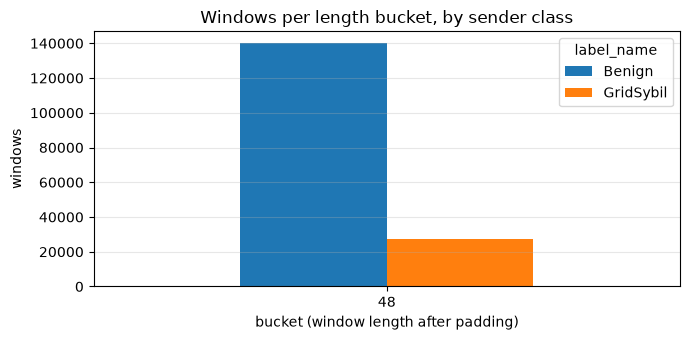

bucket with the most windows per class: {'Benign': 48, 'GridSybil': 48}


In [11]:
import matplotlib.pyplot as plt

_counts = windows.meta.pivot_table(
    index="bucket", columns="label_name", values="n_messages", aggfunc="size", fill_value=0
)
_fig, _ax = plt.subplots(figsize=(7, 3.5))
_counts.plot.bar(ax=_ax, rot=0)
_ax.set_xlabel("bucket (window length after padding)")
_ax.set_ylabel("windows")
_ax.set_title("Windows per length bucket, by sender class")
_ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
_largest = _counts.idxmax().to_dict()
print("bucket with the most windows per class:", _largest)

## Normalise with statistics from the train windows only (val and test excluded)

Every feature is scaled to mean 0 and standard deviation 1. The mean and standard deviation come from the
**real rows of the benign train windows** only (mask = 1); no GridSybil row and no val / test row is used. Padding rows and the missing `log_dtau` of the first
message of each link are ignored.

After scaling:

- real rows hold the normalised values;
- the missing `log_dtau` becomes **0**, which is exactly the train mean (the most neutral value we can give);
- padding rows are **0** in every feature, and the mask marks them (1 = real message, 0 = padding).

The same train statistics are applied to every split, so nothing from val / test leaks into the scaling.


In [12]:
import json
import platform
import shutil
import subprocess
from dataclasses import asdict
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn


class TrainNormaliser:
    """Per-feature mean / std fitted on the real rows of the train windows.

    Attributes:
        features: Feature names, in column order.
        mean: Per-feature mean, shape (n_features,).
        std: Per-feature standard deviation, shape (n_features,); a constant feature gets 1.0.
        n_values: Per-feature number of values the statistics were computed from.
    """

    def __init__(self, features: list[str]) -> None:
        self.features = list(features)
        self.mean: np.ndarray | None = None
        self.std: np.ndarray | None = None
        self.n_values: np.ndarray | None = None

    def fit(self, x_raw: np.ndarray, mask: np.ndarray, rows: np.ndarray) -> "TrainNormaliser":
        """Computes the statistics from the real rows of the selected windows.

        Args:
            x_raw: Raw values, shape (N, T, F); padding rows are 0, a missing log_dtau is NaN.
            mask: 1 = real row, 0 = padding, shape (N, T).
            rows: Boolean selector of the windows to fit on (the train windows), shape (N,).

        Returns:
            self, fitted.
        """
        picked = np.flatnonzero(rows)
        real = x_raw[picked][mask[picked].astype(bool)].astype(np.float64)  # (n_real_rows, F)
        if real.shape[0] == 0:
            raise ValueError("No real rows in the train windows; cannot fit the normaliser.")
        self.n_values = np.sum(~np.isnan(real), axis=0)
        self.mean = np.nanmean(real, axis=0)
        std = np.nanstd(real, axis=0)
        self.std = np.where(std > 0, std, 1.0)
        return self

    def apply(self, x_raw: np.ndarray, mask: np.ndarray, chunk: int = 50_000) -> np.ndarray:
        """Normalises every window; missing values and padding rows become 0.

        Args:
            x_raw: Raw values, shape (N, T, F).
            mask: 1 = real row, 0 = padding, shape (N, T).
            chunk: Windows processed at a time (keeps memory low on the full data).

        Returns:
            Normalised float32 array, shape (N, T, F).
        """
        if self.mean is None:
            raise RuntimeError("Call fit() before apply().")
        out = np.empty(x_raw.shape, dtype=np.float32)
        for start in range(0, len(x_raw), chunk):
            part = (x_raw[start : start + chunk].astype(np.float64) - self.mean) / self.std
            part = np.nan_to_num(part, nan=0.0)  # missing log_dtau -> train mean -> 0
            part[mask[start : start + chunk] == 0] = 0.0  # padding rows -> 0 in every feature
            out[start : start + chunk] = part
        return out

    def to_dict(self) -> dict:
        """Returns the statistics as plain JSON-ready values."""
        return {
            "features": self.features,
            "mean": [float(v) for v in self.mean],
            "std": [float(v) for v in self.std],
            "n_values": [int(v) for v in self.n_values],
            "fitted_on": "train windows, real rows only (mask = 1; padding and missing log_dtau ignored)",
            "missing_log_dtau": "first message of each link has no previous message; set to 0 (= train mean)",
            "padding": "padding rows are 0 in every feature; mask = 0 marks them",
        }


def check_only_log_dtau_missing(x_raw: np.ndarray, mask: np.ndarray, features: list[str]) -> None:
    """Fails if a real row has a missing value in any feature other than log_dtau."""
    missing = np.isnan(x_raw[mask.astype(bool)]).sum(axis=0)
    others = {f: int(n) for f, n in zip(features, missing) if n and f != "log_dtau"}
    assert not others, f"Unexpected missing values in real rows: {others}"

In [13]:
features = json.loads((Path(SETTINGS.prepared_dir) / "index.json").read_text())["features"]
MAX_LEN = SETTINGS.seq_len
BUCKETS = tuple(SETTINGS.buckets)
assert windows.x_raw.shape[1:] == (MAX_LEN, len(features)), windows.x_raw.shape
assert windows.mask.shape == windows.x_raw.shape[:2], windows.mask.shape
check_only_log_dtau_missing(windows.x_raw, windows.mask, features)

is_train = (windows.meta["split"] == "train").to_numpy()
assert set(windows.meta.loc[is_train, "split"]) == {"train"} and is_train.sum() < len(is_train)
assert (windows.meta.loc[is_train, "label"] == SETTINGS.benign_code).all()  # genuine train rows only
normaliser = TrainNormaliser(features).fit(windows.x_raw, windows.mask, is_train)
x_norm = normaliser.apply(windows.x_raw, windows.mask)

pd.DataFrame({"mean": normaliser.mean, "std": normaliser.std, "n_values": normaliser.n_values}, index=features).round(4)

,mean,std,n_values
claimed_pos_x,470.5405,388.2645,2115104
claimed_pos_y,633.3124,304.8953,2115104
rx_pos_x,470.8149,388.4029,2115104
rx_pos_y,633.2099,305.6809,2115104
claimed_vel_x,0.0643,7.0769,2115104
claimed_vel_y,0.2809,8.2155,2115104
rx_vel_x,0.0110,7.0493,2115104
rx_vel_y,0.2701,8.1781,2115104
claimed_acl_x,0.0048,0.8716,2115104
claimed_acl_y,-0.0134,1.2172,2115104


## Normalisation against `T48_tvt`

`T48_tvt` fitted its statistics on benign + GridSybil train rows; this dataset fits them on benign train rows only.
The table shows the shift of the mean in units of the `T48_tvt` standard deviation and the ratio of the standard
deviations (read only from `T48_tvt/metadata.json`).


In [14]:
class NormalisationComparison:
    """Compares fitted statistics with those of a reference encoder input."""

    def __init__(self, reference_metadata: pathlib.Path) -> None:
        """Reads the reference statistics.

        Args:
            reference_metadata: `metadata.json` of the reference folder (read only).
        """
        reference = json.loads(pathlib.Path(reference_metadata).read_text())["normalisation"]
        self.path = str(reference_metadata)
        self.features = reference["features"]
        self.mean = np.asarray(reference["mean"], dtype=np.float64)
        self.std = np.asarray(reference["std"], dtype=np.float64)

    def compare(self, normaliser: TrainNormaliser) -> pd.DataFrame:
        """Per feature: both means and stds, the mean shift in reference stds, and the std ratio."""
        if list(normaliser.features) != list(self.features):
            raise ValueError("feature order differs from the reference")
        return pd.DataFrame(
            {
                "mean": normaliser.mean,
                "mean_T48_tvt": self.mean,
                "mean_shift_in_ref_std": (normaliser.mean - self.mean) / self.std,
                "std": normaliser.std,
                "std_T48_tvt": self.std,
                "std_ratio": normaliser.std / self.std,
            },
            index=self.features,
        )


_comparison = NormalisationComparison(pathlib.Path(SETTINGS.reference_metadata)).compare(normaliser)
NORM_DIFF = {
    "reference": SETTINGS.reference_metadata,
    "per_feature": {
        f: {k: round(float(v), 6) for k, v in row.items()} for f, row in _comparison.to_dict(orient="index").items()
    },
    "max_abs_mean_shift_in_ref_std": round(float(_comparison["mean_shift_in_ref_std"].abs().max()), 4),
    "std_ratio_range": [
        round(float(_comparison["std_ratio"].min()), 4),
        round(float(_comparison["std_ratio"].max()), 4),
    ],
}
_train_norm = x_norm[is_train][windows.mask[is_train].astype(bool)]
print("benign train after normalisation: |mean| max", float(np.abs(_train_norm.mean(axis=0)).max()))
print(
    "max |mean shift| (ref std):",
    NORM_DIFF["max_abs_mean_shift_in_ref_std"],
    "| std ratio range:",
    NORM_DIFF["std_ratio_range"],
)
_comparison.round(4)

benign train after normalisation: |mean| max 7.645847654202953e-05
max |mean shift| (ref std): 0.2423 | std ratio range: [0.268, 1.3956]


,mean,mean_T48_tvt,mean_shift_in_ref_std,std,std_T48_tvt,std_ratio
claimed_pos_x,470.5405,489.0844,-0.0392,388.2645,472.8811,0.8211
claimed_pos_y,633.3124,644.9461,-0.0271,304.8953,428.5269,0.7115
rx_pos_x,470.8149,479.8115,-0.0228,388.4029,393.9149,0.9860
rx_pos_y,633.2099,645.0525,-0.0390,305.6809,303.2970,1.0079
claimed_vel_x,0.0643,0.0113,0.0105,7.0769,5.0710,1.3956
claimed_vel_y,0.2809,0.1580,0.0207,8.2155,5.9283,1.3858
rx_vel_x,0.0110,-0.0359,0.0066,7.0493,7.0819,0.9954
rx_vel_y,0.2701,0.2465,0.0029,8.1781,8.2030,0.9970
claimed_acl_x,0.0048,-0.0014,0.0064,0.8716,0.9617,0.9064
claimed_acl_y,-0.0134,-0.0112,-0.0017,1.2172,1.2744,0.9551


## Write the encoder input as JSON shards, one folder per split

Every window is 48 rows, so each split has one folder, `<split>/b48/`: `train`, `val`, `test` (benign) and `test_gridsybil`. Every shard holds windows of one split.

- `part-XXXXX.json` holds only what the encoder reads: the window `id`, `x` (bucket × 13, normalised,
  4 decimals) and `mask` (bucket values, 1 = real message, 0 = padding). **No labels and no vehicle ids.**
- `part-XXXXX_info.json` holds the bookkeeping for the same windows, in the same order: scenario, run,
  receiver file, receiver, sender, sender pseudonym, window index within the link, number of messages,
  bucket, label, label name and `is_attack`.

The writer refuses to write anywhere except under the allowed folder (`src/data/encoder_input`), and clears
an existing output only when `overwrite=True`.


In [15]:
class ShardedJsonWriter:
    """Writes normalised windows as JSON shards, one folder per split and bucket.

    Attributes:
        out_dir: Output folder (resolved).
        features: Feature names, in column order.
        max_len: Maximum window length (T).
        shard_size: Windows per shard.
        decimals: Decimals kept for x.
        overwrite: Whether an existing output may be cleared.
    """

    INFO_COLUMNS = [
        "scenario",
        "run",
        "receiver_file",
        "receiver",
        "sender",
        "sender_pseudo",
        "link_window_index",
        "n_messages",
        "bucket",
        "label",
        "label_name",
        "is_attack",
    ]

    def __init__(
        self,
        out_dir: str | Path,
        allowed_root: str | Path,
        features: list[str],
        max_len: int,
        shard_size: int,
        decimals: int,
        overwrite: bool = False,
    ) -> None:
        self.out_dir = Path(out_dir).resolve()
        root = Path(allowed_root).resolve()
        if not self.out_dir.is_relative_to(root):
            raise PermissionError(f"Refusing to write to {self.out_dir}: outside the allowed folder {root}.")
        self.features = list(features)
        self.max_len = max_len
        self.shard_size = shard_size
        self.decimals = decimals
        self.overwrite = overwrite

    def prepare_folder(self) -> None:
        """Creates the output folder; clears a previous output only when overwrite is set."""
        if self.out_dir.exists() and any(self.out_dir.iterdir()):
            if not self.overwrite:
                raise FileExistsError(f"{self.out_dir} is not empty; pass overwrite=True to replace it.")
            shutil.rmtree(self.out_dir)
        self.out_dir.mkdir(parents=True, exist_ok=True)

    def write_group(self, split: str, bucket: int, x: np.ndarray, mask: np.ndarray, meta: pd.DataFrame) -> list[dict]:
        """Writes the windows of one split and one bucket as shards.

        Args:
            split: Split name.
            bucket: Bucket size; x and mask are cut to this many rows.
            x: Normalised windows, shape (n, T, F).
            mask: Masks, shape (n, T).
            meta: Bookkeeping rows, same order as x.

        Returns:
            One entry per shard: split, bucket, file names and number of windows.
        """
        assert (meta["bucket"] == bucket).all() and (meta["n_messages"] <= bucket).all(), (split, bucket)
        relative = f"{split}/b{bucket:02d}"
        (self.out_dir / relative).mkdir(parents=True, exist_ok=True)
        shards = []
        for number, start in enumerate(range(0, len(meta), self.shard_size)):
            stop = min(start + self.shard_size, len(meta))
            name = f"part-{number:05d}"
            rows = meta.iloc[start:stop]
            values = np.round(x[start:stop, :bucket].astype(np.float64), self.decimals) + 0.0  # -0.0 -> 0.0
            masks = mask[start:stop, :bucket].astype(int)
            data = {
                "seq_len": bucket,
                "max_seq_len": self.max_len,
                "features": self.features,
                "windows": [
                    {"id": wid, "x": vals.tolist(), "mask": msk.tolist()}
                    for wid, vals, msk in zip(rows["window_id"], values, masks)
                ],
            }
            info = {
                "split": split,
                "bucket": bucket,
                "shard": name,
                "windows": [
                    {"id": wid, **{c: self.plain(row[c]) for c in self.INFO_COLUMNS}}
                    for wid, (_, row) in zip(rows["window_id"], rows.iterrows())
                ],
            }
            self.dump(self.out_dir / relative / f"{name}.json", data)
            self.dump(self.out_dir / relative / f"{name}_info.json", info)
            shards.append(
                {
                    "split": split,
                    "bucket": bucket,
                    "file": f"{relative}/{name}.json",
                    "info": f"{relative}/{name}_info.json",
                    "windows": int(stop - start),
                    "messages": int(rows["n_messages"].sum()),
                }
            )
        return shards

    @staticmethod
    def plain(value):
        """Turns numpy scalars into plain Python values for JSON."""
        return value.item() if isinstance(value, np.generic) else value

    @staticmethod
    def dump(path: Path, data: dict) -> None:
        """Writes compact JSON."""
        with open(path, "w") as handle:
            json.dump(data, handle, separators=(",", ":"))


SPLITS = [*INDEX.split_names, SETTINGS.attack_test_split]  # train, val, test (benign) + test_gridsybil
writer = ShardedJsonWriter(
    SETTINGS.out_dir,
    SETTINGS.allowed_out_root,
    features,
    MAX_LEN,
    SETTINGS.shard_size,
    SETTINGS.decimals,
    overwrite=True,
)
writer.prepare_folder()
shards = []
for split in SPLITS:
    for bucket in BUCKETS:
        picked = np.flatnonzero(((windows.meta["split"] == split) & (windows.meta["bucket"] == bucket)).to_numpy())
        if len(picked):
            shards += writer.write_group(split, bucket, x_norm[picked], windows.mask[picked], windows.meta.iloc[picked])
pd.DataFrame(shards).groupby(["split", "bucket"]).agg(shards=("file", "size"), windows=("windows", "sum"))

,,shards,windows
split,bucket,,
test,48,2,13405
test_gridsybil,48,3,27064
train,48,12,112890
val,48,2,13584


## Write `metadata.json`

One file that says what is in the folder and how it was made: feature order, maximum length and buckets,
settings, the train normalisation statistics, the train / val / test split (vehicle counts and ids per split,
windows per split and class, padding share per split), counts per split × bucket × class (windows, messages, padding
share), the overall padding share (and what it would be if every window were padded to 48), the shard list,
where the source data came from, and the code / library versions.

Padding share = padding rows / all stored rows, where a window stores `bucket` rows.


In [16]:
class MetadataWriter:
    """Builds and writes metadata.json for the encoder input folder."""

    def __init__(self, settings, features: list[str]) -> None:
        self.settings = settings
        self.features = features

    @staticmethod
    def padding_share(messages: int, stored_rows: int) -> float:
        """Share of stored rows that are padding."""
        return round(1.0 - messages / stored_rows, 4) if stored_rows else 0.0

    def counts_by_split_bucket_class(self, meta: pd.DataFrame) -> dict:
        """Windows, messages and padding share per split, bucket and class."""
        result = {}
        for (split, bucket, name), group in meta.groupby(["split", "bucket", "label_name"]):
            messages = int(group["n_messages"].sum())
            result.setdefault(split, {}).setdefault(f"b{int(bucket):02d}", {})[name] = {
                "windows": int(len(group)),
                "messages": messages,
                "padding_share": self.padding_share(messages, int(len(group)) * int(bucket)),
            }
        return result

    def padding_overall(self, meta: pd.DataFrame) -> dict:
        """Overall and per-bucket padding share, plus the share if every window were padded to the maximum."""
        messages = int(meta["n_messages"].sum())
        per_bucket = {}
        for bucket, group in meta.groupby("bucket"):
            per_bucket[f"b{int(bucket):02d}"] = self.padding_share(
                int(group["n_messages"].sum()), int(len(group)) * int(bucket)
            )
        return {
            "overall": self.padding_share(messages, int(meta["bucket"].sum())),
            "if_all_padded_to_max": self.padding_share(messages, len(meta) * self.settings.seq_len),
            "per_bucket": per_bucket,
            "windows": int(len(meta)),
            "messages": messages,
        }

    def source(self) -> dict:
        """Source folder and the provenance recorded in its index.json."""
        index_path = Path(self.settings.prepared_dir) / "index.json"
        index = json.loads(index_path.read_text())
        return {
            "prepared_dir": str(self.settings.prepared_dir),
            "scenarios": list(self.settings.scenarios),
            "index_provenance": index.get("provenance", {}),
        }

    @staticmethod
    def provenance() -> dict:
        """Git commit / dirty flag, library versions and a UTC timestamp."""

        def git(*args: str) -> str:
            try:
                return subprocess.run(["git", *args], capture_output=True, text=True, check=True).stdout.strip()
            except (OSError, subprocess.CalledProcessError):
                return ""

        return {
            "git_commit": git("rev-parse", "HEAD") or None,
            "git_dirty": bool(git("status", "--porcelain")),
            "python": platform.python_version(),
            "numpy": np.__version__,
            "pandas": pd.__version__,
            "sklearn": sklearn.__version__,
            "platform": platform.platform(),
            "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        }

    def write(
        self,
        out_dir: Path,
        meta: pd.DataFrame,
        normaliser: TrainNormaliser,
        shards: list[dict],
        counts: dict,
        split_report: dict,
        extra: dict,
    ) -> dict:
        """Writes metadata.json and returns its content."""
        content = {
            "features": self.features,
            "max_seq_len": self.settings.seq_len,
            "buckets": [int(b) for b in self.settings.buckets],
            "layout": "<split>/b<bucket:02d>/part-XXXXX.json (+ _info.json); x and mask cut to the bucket size",
            "settings": {k: (list(v) if isinstance(v, tuple) else v) for k, v in asdict(self.settings).items()},
            "normalisation": normaliser.to_dict(),
            "counts": counts,
            "counts_by_split_bucket_class": self.counts_by_split_bucket_class(meta),
            "padding": self.padding_overall(meta),
            "padding_by_split": {s: self.padding_overall(g) for s, g in meta.groupby("split")},
            "split": {
                **split_report,
                "windows": {s: int(n) for s, n in meta.groupby("split").size().items()},
                "windows_by_class": {
                    s: {c: int(n) for c, n in g.groupby("label_name").size().items()} for s, g in meta.groupby("split")
                },
                "vehicles_with_windows_by_class": {
                    s: {
                        c: int(
                            gg["sender"].astype(str).radd(gg["scenario"].str.rsplit("_", n=1).str[1] + ":").nunique()
                        )
                        for c, gg in g.groupby("label_name")
                    }
                    for s, g in meta.groupby("split")
                },
            },
            **extra,
            "shards": shards,
            "source": self.source(),
            "provenance": self.provenance(),
        }
        with open(Path(out_dir) / "metadata.json", "w") as handle:
            json.dump(content, handle, indent=1, default=ShardedJsonWriter.plain)
        return content


RULE = {
    "dataset": "benign + GridSybil T = 48, 80 / 10 / 10 by sender vehicle, benign only for one-class training",
    "benign_only": SELECTION["rule"],
    "normalisation_source": "mean / std of the real rows of the benign train windows of this dataset, applied to every split",
    "split": "identical vehicle -> split assignment as T48_tvt (subset of it); no RULE 3 change",
}
SPLIT_REPORT_BENIGN = {
    "rule": SPLIT_REPORT["rule"],
    "reference": "T48_tvt split; per_stratum / vehicles count all benign + GridSybil vehicles of that split",
    "per_stratum": SPLIT_REPORT["per_stratum"],
    "vehicles_T48_tvt": SPLIT_REPORT["vehicles"],
    "vehicle_ids": {
        s: sorted({f"{sc.rsplit('_', 1)[1]}:{v}" for sc, v in zip(g["scenario"], g["sender"])})
        for s, g in windows.meta.groupby("split")
    },
}
metadata = MetadataWriter(SETTINGS, features).write(
    writer.out_dir,
    windows.meta,
    normaliser,
    shards,
    windows.counts,
    SPLIT_REPORT_BENIGN,
    {"rule": RULE, "selection": SELECTION, "normalisation_vs_T48_tvt": NORM_DIFF},
)
print(
    "padding share overall:",
    metadata["padding"]["overall"],
    "| if all padded to 48:",
    metadata["padding"]["if_all_padded_to_max"],
)
print("padding share per split:", {s: p["overall"] for s, p in metadata["padding_by_split"].items()})
print("sender vehicles with windows:", json.dumps(metadata["split"]["vehicles_with_windows_by_class"]))
pd.DataFrame(
    {
        (s, b): {c: v["windows"] for c, v in d.items()}
        for s, by_bucket in metadata["counts_by_split_bucket_class"].items()
        for b, d in by_bucket.items()
    }
).T.fillna(0).astype(int)

padding share overall: 0.6139 | if all padded to 48: 0.6139
padding share per split: {'test': 0.6142, 'test_gridsybil': 0.6321, 'train': 0.6097, 'val': 0.6126}
sender vehicles with windows: {"test": {"Benign": 401}, "test_gridsybil": {"GridSybil": 173}, "train": {"Benign": 3223}, "val": {"Benign": 402}}


,,Benign,GridSybil
test,b48,13405,0
test_gridsybil,b48,0,27064
train,b48,112890,0
val,b48,13584,0


## Read back and check the written files

We re-open every shard and check:

- every `x` is bucket × 13 with no missing value, and the shard's `seq_len` equals its bucket;
- every `mask` has bucket values, is a run of ones followed by zeros, and its sum equals `n_messages` in the
  info file; the bucket is the smallest one that fits `n_messages`;
- padding rows are all zero;
- window ids are unique across all shards, and no sender vehicle appears in two splits (the split is by
  sender vehicle, so this must hold);
- the total number of windows and the total mask sum equal the kept windows and kept messages.


In [17]:
class EncoderInputChecks:
    """Re-reads the written shards and checks shapes, masks, padding, ids and the split."""

    def __init__(self, out_dir: Path, buckets: tuple[int, ...], n_features: int) -> None:
        self.out_dir = Path(out_dir)
        self.buckets = tuple(buckets)
        self.n_features = n_features

    def smallest_bucket(self, n: int) -> int:
        """The smallest bucket that holds n messages."""
        return next(b for b in self.buckets if b >= n)

    def check_shard(self, entry: dict) -> tuple[list[dict], int]:
        """Checks one shard against its info file; returns its info rows and its mask sum."""
        bucket = entry["bucket"]
        data = json.loads((self.out_dir / entry["file"]).read_text())
        info = json.loads((self.out_dir / entry["info"]).read_text())["windows"]
        assert data["seq_len"] == bucket, (entry["file"], data["seq_len"])
        assert len(data["windows"]) == len(info) == entry["windows"], entry
        mask_sum = 0
        for window, row in zip(data["windows"], info):
            wid = window["id"]
            x = np.asarray(window["x"], dtype=np.float64)
            mask = np.asarray(window["mask"], dtype=np.int64)
            n = row["n_messages"]
            assert wid == row["id"], (wid, row["id"])
            assert x.shape == (bucket, self.n_features), (wid, x.shape)
            assert not np.isnan(x).any(), f"missing value in {wid}"
            assert mask.shape == (bucket,), (wid, mask.shape)
            assert int(mask.sum()) == n and (mask[:n] == 1).all() and (mask[n:] == 0).all(), f"bad mask in {wid}"
            assert row["bucket"] == bucket == self.smallest_bucket(n), f"wrong bucket for {wid}"
            assert np.all(x[n:] == 0.0), f"non-zero padding in {wid}"
            mask_sum += n
        return info, mask_sum

    def run(self, shards: list[dict], expected_windows: int, expected_messages: int) -> dict:
        """Runs every check over all shards; returns a short summary."""
        ids, vehicle_splits, mask_total = set(), {}, 0
        n_ids = 0
        for entry in shards:
            info, mask_sum = self.check_shard(entry)
            mask_total += mask_sum
            for row in info:
                n_ids += 1
                ids.add(row["id"])
                vehicle = f"{row['scenario'].split('_')[-1]}:{row['sender']}"
                vehicle_splits.setdefault(vehicle, set()).add(entry["split"])
        straddling = [v for v, s in vehicle_splits.items() if len(s) > 1]
        assert n_ids == len(ids), f"{n_ids - len(ids)} duplicate window ids"
        assert not straddling, f"sender vehicles in more than one split: {straddling[:5]}"
        assert n_ids == expected_windows, (n_ids, expected_windows)
        assert mask_total == expected_messages, (mask_total, expected_messages)
        return {
            "shards": len(shards),
            "windows": n_ids,
            "messages": mask_total,
            "sender_vehicles": len(vehicle_splits),
            "vehicles_in_two_splits": len(straddling),
        }


def kept_count(counts: dict, keys: tuple[str, ...], fallback: int) -> int:
    """The first of `keys` found in the counts, else the fallback (computed from the windows)."""
    return int(next((counts[k] for k in keys if k in counts), fallback))


expected_windows = kept_count(windows.counts, ("windows_kept", "windows"), len(windows.meta))
expected_messages = kept_count(windows.counts, ("messages_kept", "messages"), int(windows.meta["n_messages"].sum()))
assert expected_windows == len(windows.meta) and expected_messages == int(windows.mask.sum())
check_summary = EncoderInputChecks(writer.out_dir, BUCKETS, len(features)).run(
    metadata["shards"], expected_windows, expected_messages
)
_labels = {}
for _entry in metadata["shards"]:
    for _row in json.loads((writer.out_dir / _entry["info"]).read_text())["windows"]:
        _labels.setdefault(_entry["split"], set()).add(_row["label"])
assert all(_labels[s] == {SETTINGS.benign_code} for s in INDEX.split_names), _labels
assert _labels[SETTINGS.attack_test_split] <= set(SETTINGS.attack_codes), _labels
for _entry in metadata["shards"][:3]:
    _keys = {k for w in json.loads((writer.out_dir / _entry["file"]).read_text())["windows"] for k in w}
    assert _keys == {"id", "x", "mask"}, _keys  # no labels in feature shards
print("labels per split:", {s: sorted(v) for s, v in _labels.items()})
print("All checks passed:", check_summary)

labels per split: {'train': [0], 'val': [0], 'test': [0], 'test_gridsybil': [16]}
All checks passed: {'shards': 19, 'windows': 166943, 'messages': 3093895, 'sender_vehicles': 4199, 'vehicles_in_two_splits': 0}
